<a href="https://colab.research.google.com/github/FarzanaAkter123/AI-Search-Algorithms/blob/main/UCS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

UCS Traversal: ['A', 'B', 'D', 'C', 'E', 'H']
Shortest Path: ['A', 'B', 'D', 'H']
Total Cost: 6


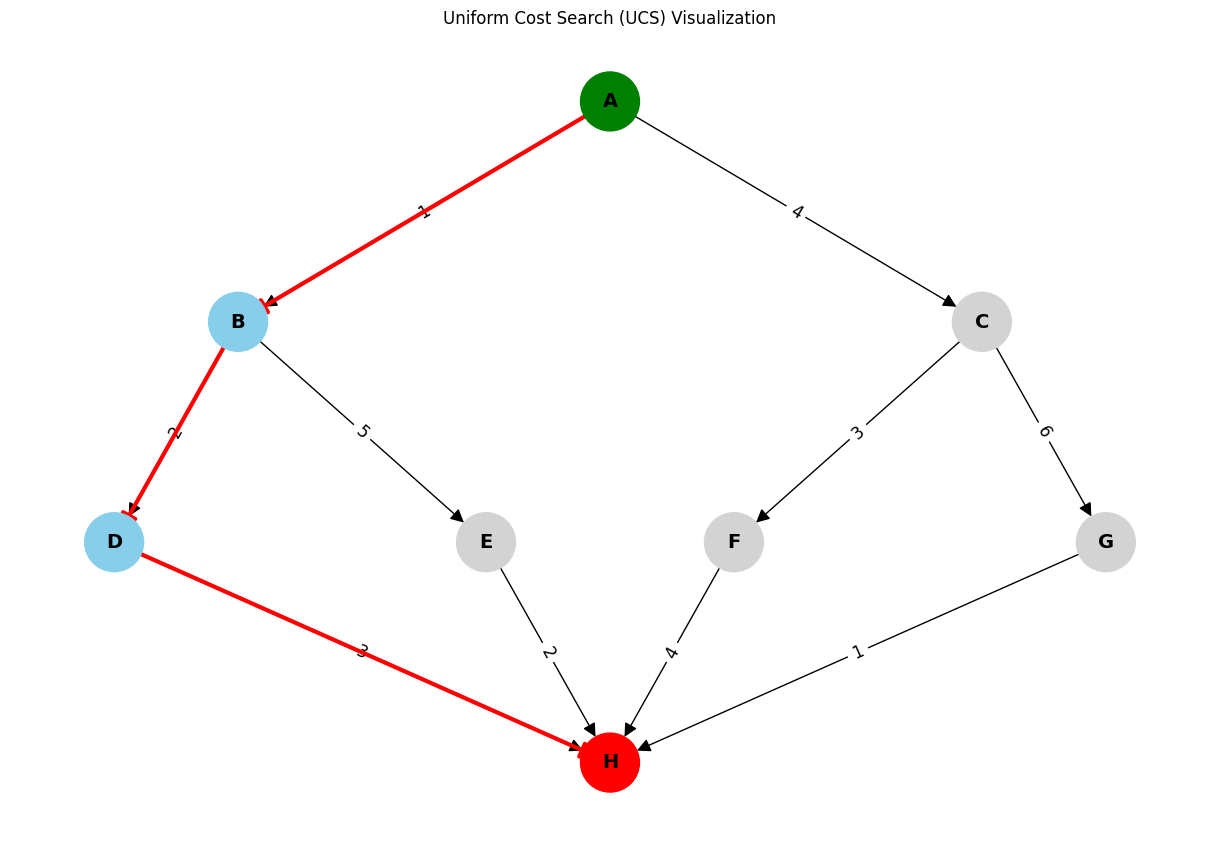

In [2]:
import heapq
import networkx as nx
import matplotlib.pyplot as plt

# Create a weighted graph
graph = {
    'A': [('B', 1), ('C', 4)],
    'B': [('D', 2), ('E', 5)],
    'C': [('F', 3), ('G', 6)],
    'D': [('H', 3)],
    'E': [('H', 2)],
    'F': [('H', 4)],
    'G': [('H', 1)],
    'H': []
}

# UCS Algorithm
def ucs(graph, start, goal):

    priority_queue = [(0, start, [start])]
    visited = set()
    traversal_order = []

    while priority_queue:

        cost, node, path = heapq.heappop(priority_queue)

        if node in visited:
            continue

        visited.add(node)
        traversal_order.append(node)

        if node == goal:
            return path, cost, traversal_order

        for neighbor, weight in graph[node]:

            if neighbor not in visited:
                new_cost = cost + weight

                heapq.heappush(
                    priority_queue,
                    (new_cost, neighbor, path + [neighbor])
                )

    return None, float('inf'), traversal_order


# Run UCS
start_node = 'A'
goal_node = 'H'

path, cost, result = ucs(
    graph, start_node, goal_node
)

print("UCS Traversal:", result)
print("Shortest Path:", path)
print("Total Cost:", cost)


# Create weighted NetworkX graph
G = nx.DiGraph()

for node in graph:
    for neighbor, weight in graph[node]:
        G.add_edge(node, neighbor, weight=weight)

pos = {
    'A': (0, 3),
    'B': (-1.5, 2),
    'C': (1.5, 2),
    'D': (-2, 1),
    'E': (-0.5, 1),
    'F': (0.5, 1),
    'G': (2, 1),
    'H': (0, 0)
}

plt.figure(figsize=(12, 8))

node_colors = []

for node in G.nodes():

    if node == start_node:
        node_colors.append('green')

    elif node == goal_node:
        node_colors.append('red')

    elif node in path:
        node_colors.append('skyblue')

    else:
        node_colors.append('lightgray')


nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=node_colors,
    node_size=1800,
    font_size=14,
    font_weight='bold',
    arrows=True,
    arrowsize=20
)

# Display edge weights
edge_labels = nx.get_edge_attributes(G, 'weight')

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=12
)

# Highlight shortest path
if path:
    path_edges = list(zip(path, path[1:]))

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=path_edges,
        edge_color='red',
        width=3,
        arrows=True,
        arrowsize=25
    )

plt.title("Uniform Cost Search (UCS) Visualization")
plt.axis('off')
plt.show()